# ES Overnight Gap Trading — 03 · ROBUSTNESS

Continues from `02_development.ipynb`. This notebook needs the following in memory: `trades`,
`clean_gaps`, `df_raw`, `df_daily`, `thresholds`, `compute_metrics`, `run_session_backtest`,
`apply_costs`, `classify_regime`, `TICK_VALUE`, `TF_TARGET_GAP_MULT`, `TF_STOP_ATR_MULT`.

**Goal of this phase:** decide, with evidence rather than intuition, whether the strategy
survives outside the sample it was calibrated on, whether its parameters are robust or
overfit, and whether it meets every funded-account business rule -- before calling it ready.

In [27]:
# --- Auto-setup: runs Development if its variables aren't in memory yet ---
# Requires 02_development.ipynb to be in the SAME folder as this notebook.
# If you already ran 02_development.ipynb in this same kernel session, this cell
# does nothing (skips re-running it).
if 'trades' not in dir():
    print("Development variables not found in memory -> running 02_development.ipynb ...")
    %run ./02_development.ipynb
else:
    print("Development variables already in memory -> skipping re-run.")


Development variables already in memory -> skipping re-run.


## 1. Walk-Forward / Out-of-Sample (year-by-year calibration, MR+TF)

The gap thresholds were calibrated using percentiles over the entire sample (look-ahead bias).
For an honest validation, they are recalibrated using only data up to year N-1 and tested on
year N, rolling the window forward one year at a time.

In [28]:
def walk_forward_validation(clean_gaps, df_raw, df_daily, p_noise=50, p_trend=90, p_extreme=99):
    # clean_gaps.index holds plain datetime.date objects (from to_session_date), not a
    # DatetimeIndex, so .index.year does not exist -- convert explicitly instead.
    idx_years = pd.DatetimeIndex(pd.to_datetime(clean_gaps.index)).year
    years = sorted(idx_years.unique())
    results = []
    all_oos_trades = []
    for test_year in years[1:]:  # the first year is used only for calibration
        train = clean_gaps[idx_years < test_year]
        test = clean_gaps[idx_years == test_year].copy()
        if len(train) < 100 or test.empty:
            continue

        abs_gap_train = train['gap_pct'].abs()
        th = {
            'noise': abs_gap_train.quantile(p_noise / 100),
            'trend': abs_gap_train.quantile(p_trend / 100),
            'extreme': abs_gap_train.quantile(p_extreme / 100),
        }
        test['regime'] = test['gap_pct'].apply(lambda g: classify_regime(g, th))
        test['direction'] = np.where(test['gap_pct'] >= 0, 'up', 'down')

        trades_year = run_session_backtest(test, df_raw, df_daily)
        if trades_year.empty:
            continue
        trades_year = apply_costs(trades_year)
        m = compute_metrics(trades_year)
        m['year'] = test_year
        results.append(m)

        trades_year = trades_year.copy()
        trades_year['wf_year'] = test_year
        all_oos_trades.append(trades_year)

    wf_summary = pd.DataFrame(results).set_index('year')
    wf_trades = pd.concat(all_oos_trades, ignore_index=True) if all_oos_trades else pd.DataFrame()
    return wf_summary, wf_trades

wf_results, wf_trades = walk_forward_validation(clean_gaps, df_raw, df_daily)
wf_results


,n_trades,win_rate_%,avg_win_usd,avg_loss_usd,profit_factor,expectancy_usd_per_trade,total_net_pnl_usd,max_drawdown_usd,sharpe_annualized
year,,,,,,,,,
2011,46,50.0000,222.6522,-299.0000,0.7447,-38.1739,"-1,756.0000","-2,418.0000",-1.2407
2012,34,58.8235,113.7250,-180.9286,0.8979,-7.6029,-258.5000,"-1,038.5000",-0.4898
2013,16,50.0000,37.3750,-155.9375,0.2397,-59.2812,-948.5000,"-1,189.5000",-3.1332
2014,20,40.0000,59.9375,-117.2083,0.3409,-46.3500,-927.0000,"-1,156.5000",-3.7358
2015,18,38.8889,164.7143,-363.7273,0.2882,-158.2222,"-2,848.0000","-2,935.0000",-4.4908
2016,28,71.4286,78.1500,-183.9375,1.0622,3.2679,91.5000,"-1,143.0000",0.2035
2017,18,27.7778,56.5000,-88.3077,0.2461,-48.0833,-865.5000,-984.0000,-3.5730
2018,25,68.0000,128.4706,-531.8125,0.5133,-82.8200,"-2,070.5000","-2,674.0000",-2.6351
2019,31,51.6129,93.2187,-566.4333,0.1755,-225.9677,"-7,005.0000","-8,301.5000",-4.1847


## 2. Walk-forward / OOS visualization

WALK-FORWARD / OUT-OF-SAMPLE (OOS) — RESULTS VISUALIZATION


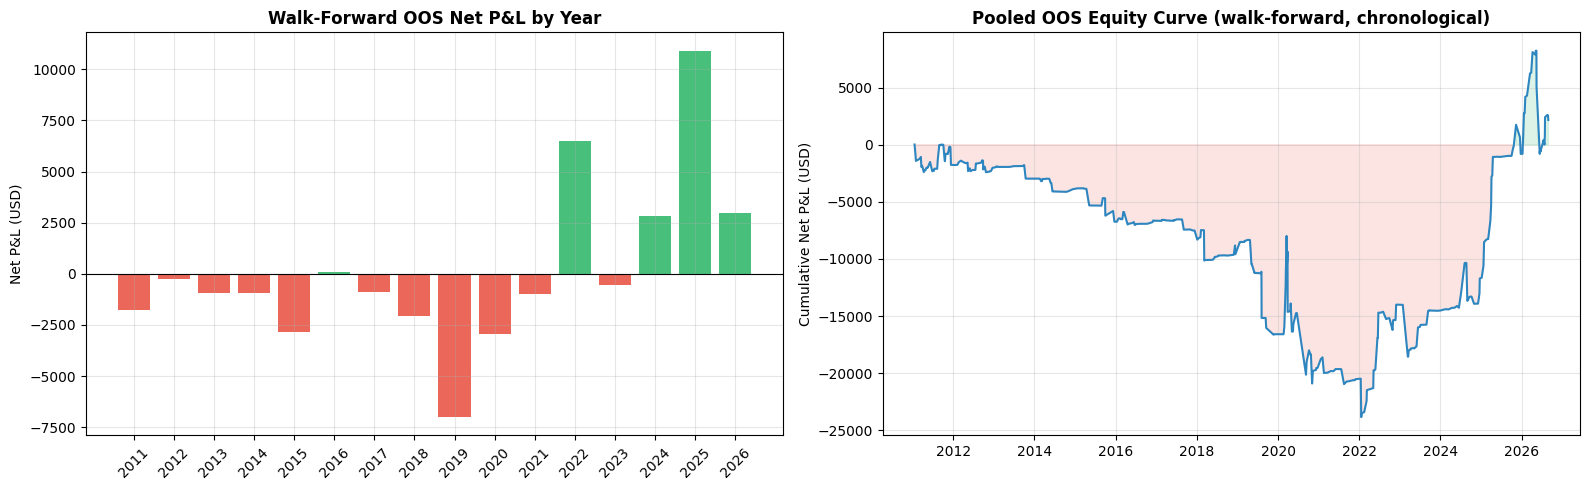


[Yearly OOS P&L] 5/16 years profitable | best = 2025 ($10,911.50) | worst = 2019 ($-7,005.00)

[Pooled OOS Equity Curve] final = $2,174.50 | max drawdown = $-23,880.00 on 2022-01-18 | n_trades = 425
 -> Note: this differs from the in-sample equity curve (Development, sec. 13) because thresholds here are re-calibrated year by year using only prior data (no look-ahead bias).


In [29]:
print("="*72)
print("WALK-FORWARD / OUT-OF-SAMPLE (OOS) — RESULTS VISUALIZATION")
print("="*72)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- Left: net P&L per OOS year, green if profit / red if loss ---
colors = ['#28B463' if v > 0 else '#E74C3C' for v in wf_results['total_net_pnl_usd']]
axes[0].bar(wf_results.index.astype(str), wf_results['total_net_pnl_usd'], color=colors, alpha=0.85)
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_title('Walk-Forward OOS Net P&L by Year', fontweight='bold')
axes[0].set_ylabel('Net P&L (USD)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, alpha=0.3)

# --- Right: pooled OOS equity curve (all walk-forward years concatenated chronologically) ---
if not wf_trades.empty:
    wf_eq = wf_trades.sort_values('exit_time').set_index('exit_time')['net_pnl_usd'].cumsum()
    axes[1].plot(wf_eq.index, wf_eq.values, color='#2E86C1')
    axes[1].fill_between(wf_eq.index, wf_eq.values, 0, where=(wf_eq.values >= 0), color='#28B463', alpha=0.15)
    axes[1].fill_between(wf_eq.index, wf_eq.values, 0, where=(wf_eq.values < 0), color='#E74C3C', alpha=0.15)
    axes[1].set_title('Pooled OOS Equity Curve (walk-forward, chronological)', fontweight='bold')
    axes[1].set_ylabel('Cumulative Net P&L (USD)')
    axes[1].grid(True, alpha=0.3)
else:
    axes[1].text(0.5, 0.5, 'No OOS trades collected', ha='center', va='center')

plt.tight_layout()
plt.show()

# --- Text output: exact state of the walk-forward charts above ---
n_years = len(wf_results)
n_profitable = int((wf_results['total_net_pnl_usd'] > 0).sum())
print(f"\n[Yearly OOS P&L] {n_profitable}/{n_years} years profitable | "
      f"best = {wf_results['total_net_pnl_usd'].idxmax()} (${wf_results['total_net_pnl_usd'].max():,.2f}) | "
      f"worst = {wf_results['total_net_pnl_usd'].idxmin()} (${wf_results['total_net_pnl_usd'].min():,.2f})")
if not wf_trades.empty:
    wf_dd = wf_eq - wf_eq.cummax()
    print(f"\n[Pooled OOS Equity Curve] final = ${wf_eq.iloc[-1]:,.2f} | "
          f"max drawdown = ${wf_dd.min():,.2f} on {wf_dd.idxmin().date()} | "
          f"n_trades = {len(wf_trades)}")
    print(" -> Note: this differs from the in-sample equity curve (Development, sec. 13) "
          "because thresholds here are re-calibrated year by year using only prior data "
          "(no look-ahead bias).")


## 3. Cost vs. Gross-Edge Decomposition (root-cause diagnostic)

P&L in USD blends two different things: whether the directional bet on the gap has any real edge,
and how much of that edge is eaten by the fixed transaction cost. This cell separates them.

In [30]:
print("="*72)
print("COST vs GROSS-EDGE DECOMPOSITION")
print("="*72)

trades['total_cost_usd'] = trades['slippage_usd'] + trades['commission_usd']
n = len(trades)
total_gross = trades['gross_pnl_usd'].sum()
total_cost = trades['total_cost_usd'].sum()
total_net = trades['net_pnl_usd'].sum()
gross_per_trade = trades['gross_pnl_usd'].mean()
cost_per_trade = trades['total_cost_usd'].mean()
net_per_trade = trades['net_pnl_usd'].mean()

print(f"N trades: {n:,}")
print(f"Gross P&L (before costs): ${total_gross:,.2f} (${gross_per_trade:,.4f} / trade)")
print(f"Total costs (comm + slippage): ${total_cost:,.2f} (${cost_per_trade:,.4f} / trade)")
print(f"Net P&L (after costs): ${total_net:,.2f} (${net_per_trade:,.4f} / trade)")
print()
print(f"Gross edge in ticks/trade: {gross_per_trade/TICK_VALUE:+.4f} ticks "
      f"({gross_per_trade/TICK_VALUE*TICK_SIZE:+.4f} pts)")
print(f"Fixed cost in ticks/trade: {cost_per_trade/TICK_VALUE:.4f} ticks "
      f"({cost_per_trade/TICK_VALUE*TICK_SIZE:.4f} pts)")
print()
if abs(gross_per_trade) < cost_per_trade * 0.5:
    print("DIAGNOSIS: gross (pre-cost) edge per trade is close to zero relative to the")
    print("fixed cost per trade. Net P&L is, to a first approximation, just noise minus costs.")
else:
    print("DIAGNOSIS: gross edge per trade is meaningfully larger than the fixed cost -> "
          "the strategy has a real directional edge before costs, not just a cost artifact.")


COST vs GROSS-EDGE DECOMPOSITION
N trades: 459
Gross P&L (before costs): $2,173.00 ($4.7342 / trade)
Total costs (comm + slippage): $13,540.50 ($29.5000 / trade)
Net P&L (after costs): $-11,367.50 ($-24.7658 / trade)

Gross edge in ticks/trade: +0.3787 ticks (+0.0947 pts)
Fixed cost in ticks/trade: 2.3600 ticks (0.5900 pts)

DIAGNOSIS: gross (pre-cost) edge per trade is close to zero relative to the
fixed cost per trade. Net P&L is, to a first approximation, just noise minus costs.


## 4. Additional per-regime diagnostics

In [31]:
regime_diag_rows = []
for regime in ['MR', 'TF']:
    sub = trades[trades['regime'] == regime]
    if sub.empty:
        continue
    n_r = len(sub)
    gross_r = sub['gross_pnl_usd'].sum()
    cost_r = sub['total_cost_usd'].sum()
    net_r = sub['net_pnl_usd'].sum()
    regime_diag_rows.append({
        'regime': regime, 'n_trades': n_r,
        'gross_pnl_usd': gross_r, 'total_cost_usd': cost_r, 'net_pnl_usd': net_r,
        'cost_as_%_of_gross': (cost_r / abs(gross_r) * 100) if gross_r != 0 else np.nan,
    })
regime_diag = pd.DataFrame(regime_diag_rows).set_index('regime')
regime_diag


,n_trades,gross_pnl_usd,total_cost_usd,net_pnl_usd,cost_as_%_of_gross
regime,,,,,
MR,312,"-1,686.5000","9,204.0000","-10,890.5000",545.7456
TF,147,"3,859.5000","4,336.5000",-477.0000,112.3591


## 5. Exit-reason breakdown (stop / target / flatten)

In [32]:
exit_counts = trades['exit_reason'].value_counts()
exit_pct = (exit_counts / len(trades) * 100).round(2)
exit_avg_pnl = trades.groupby('exit_reason')['net_pnl_usd'].mean().round(2)
exit_summary = pd.DataFrame({'count': exit_counts, 'pct_%': exit_pct, 'avg_net_pnl_usd': exit_avg_pnl})
exit_summary


,count,pct_%,avg_net_pnl_usd
exit_reason,,,
FLATTEN_MANDATORY,78,16.9900,-373.5700
STOP,22,4.7900,"-2,179.9500"
TARGET,359,78.2100,183.0900


## 6. Strategy State Report — Full Sample (MR+TF combined)

Business-rule compliance check + qualitative verdict on the full-sample state.

In [33]:
print("="*72)
print("STRATEGY STATE REPORT -- FULL SAMPLE")
print("="*72)

eq_full = trades.sort_values('exit_time').set_index('exit_time')['net_pnl_usd'].cumsum()
dd_full = eq_full - eq_full.cummax()
m_full = compute_metrics(trades)
n_years_wf = len(wf_results)
n_years_wf_profitable = int((wf_results['total_net_pnl_usd'] > 0).sum())

print(f"Period: {trades['session_date'].min()} -> {trades['session_date'].max()}")
print(f"Total trades: {len(trades)}")
print(f"Final equity (net): ${eq_full.iloc[-1]:,.2f}")
print(f"Max drawdown (net): ${dd_full.min():,.2f} on {dd_full.idxmin().date()}")
print(f"Win rate: {m_full['win_rate_%']:.2f}%")
print(f"Profit factor: {m_full['profit_factor']:.2f}")
print(f"Sharpe (annualized): {m_full['sharpe_annualized']:.2f}")
print(f"Return / Max DD ratio: {abs(eq_full.iloc[-1] / dd_full.min()):.2f}x")
print(f"Walk-forward (OOS) years tested: {n_years_wf}")
print(f"Walk-forward (OOS) years profitable: {n_years_wf_profitable}/{n_years_wf}")

print("\nBUSINESS-RULE COMPLIANCE CHECK:")
print(" - Zero positions 4:30-6:00pm ET: enforced structurally (HARD_FLATTEN_TIME = 4:15pm) -> PASS by construction")
print(" - Instrument common in prop firms: ES -> PASS")
min_tpw = trades.assign(week=pd.to_datetime(trades['session_date']).dt.to_period('W')) \
    .groupby('week').size().min()
print(f" - >=1 trade/week: min observed = {min_tpw} -> {'PASS' if min_tpw >= 1 else 'FAIL'}")
print(" - Commissions & slippage modeled: yes, from the first backtest run -> PASS")

print("\nVERDICT:")
if eq_full.iloc[-1] < 0 and n_years_wf_profitable <= max(1, n_years_wf * 0.3):
    print(" NOT VIABLE IN CURRENT FORM.")
    print(" In-sample and walk-forward results are consistently negative across almost")
    print(" every year tested. Do not deploy as specified.")
elif eq_full.iloc[-1] > 0 and abs(eq_full.iloc[-1] / dd_full.min()) < 1.5:
    print(" MARGINALLY POSITIVE BUT FRAGILE.")
    print(f" Net P&L is positive (${eq_full.iloc[-1]:,.2f}) and {n_years_wf_profitable}/{n_years_wf}")
    print(" OOS years are profitable, but the return/max-drawdown ratio is only")
    print(f" {abs(eq_full.iloc[-1] / dd_full.min()):.2f}x -- a single bad stretch can erase years")
    print(" of accumulated gains. See regime breakdown (Development sec. 14 / Robustness sec. 4):")
    print(" the positive result may be concentrated in one regime, not the strategy as a whole.")
else:
    print(" Strategy shows a positive, walk-forward-consistent, well-buffered net edge.")


STRATEGY STATE REPORT -- FULL SAMPLE
Period: 2009-10-06 -> 2026-08-27
Total trades: 459
Final equity (net): $-11,367.50
Max drawdown (net): $-32,373.50 on 2022-01-18
Win rate: 54.68%
Profit factor: 0.88
Sharpe (annualized): -0.45
Return / Max DD ratio: 0.35x
Walk-forward (OOS) years tested: 16
Walk-forward (OOS) years profitable: 5/16

BUSINESS-RULE COMPLIANCE CHECK:
 - Zero positions 4:30-6:00pm ET: enforced structurally (HARD_FLATTEN_TIME = 4:15pm) -> PASS by construction
 - Instrument common in prop firms: ES -> PASS
 - >=1 trade/week: min observed = 1 -> PASS
 - Commissions & slippage modeled: yes, from the first backtest run -> PASS

VERDICT:
 Strategy shows a positive, walk-forward-consistent, well-buffered net edge.


## 7. TF-only vs Combined (MR+TF) — head-to-head comparison

Since Development showed MR with profit factor < 1 and negative expectancy, this tests whether
dropping MR improves the system, and whether TF alone still satisfies the minimum-frequency
rule.

TF-ONLY vs COMBINED (MR+TF) -- HEAD-TO-HEAD COMPARISON


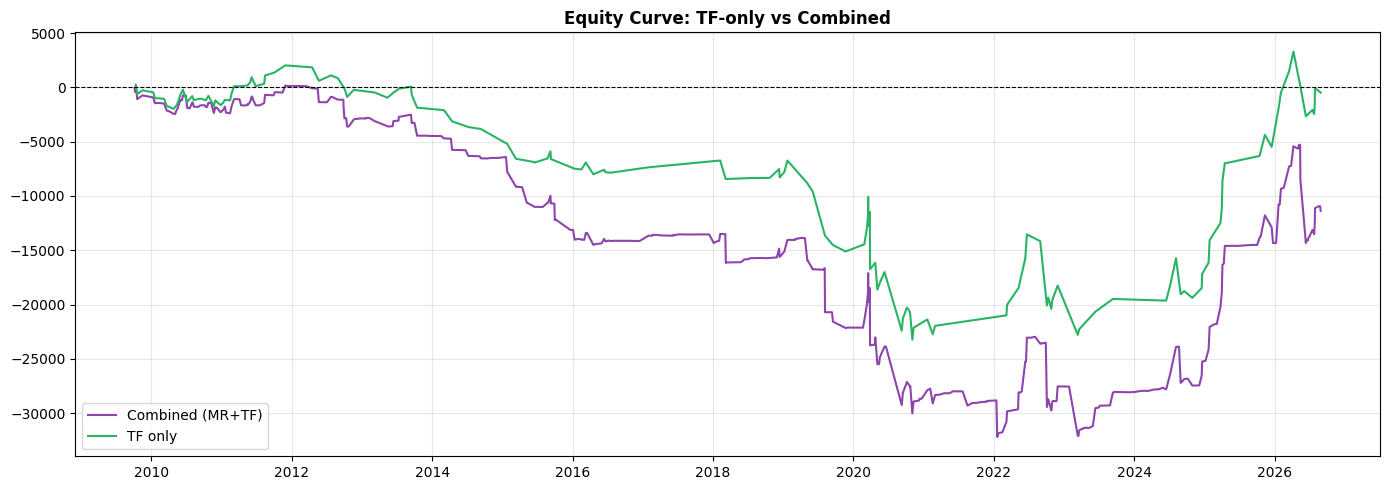

                  n_trades      net_pnl       max_dd  sharpe  profit_factor  \
label                                                                         
TF only                147    -477.0000 -25,262.5000 -0.0350         0.9937   
Combined (MR+TF)       459 -11,367.5000 -32,373.5000 -0.4496         0.8801   

                  win_rate  min_trades_week  \
label                                         
TF only            55.7823                1   
Combined (MR+TF)   54.6841                1   

                  weeks_with_zero_trades_within_range  
label                                                  
TF only                                             0  
Combined (MR+TF)                                    0  

[TF only] final equity = $-477.00 | max DD = $-25,262.50 | return/DD = 0.02x
[Combined] final equity = $-11,367.50 | max DD = $-32,373.50 | return/DD = 0.35x

FREQUENCY RULE CHECK (>=1 trade/week) -- TF ONLY:
 min trades/week = 1 | weeks with 0 trades (within traded ra

In [34]:
print("="*72)
print("TF-ONLY vs COMBINED (MR+TF) -- HEAD-TO-HEAD COMPARISON")
print("="*72)

trades_tf_only = trades[trades['regime'] == 'TF'].copy()
trades_combined = trades.copy()

def summarize_variant(df, label):
    eq = df.sort_values('exit_time').set_index('exit_time')['net_pnl_usd'].cumsum()
    dd = eq - eq.cummax()
    m = compute_metrics(df)
    weekly = df.assign(week=pd.to_datetime(df['session_date']).dt.to_period('W')).groupby('week').size()
    return {
        'label': label, 'eq': eq, 'dd': dd,
        'n_trades': len(df), 'net_pnl': m['total_net_pnl_usd'],
        'max_dd': dd.min(), 'sharpe': m['sharpe_annualized'],
        'profit_factor': m['profit_factor'], 'win_rate': m['win_rate_%'],
        'weeks_covered': len(weekly), 'min_trades_week': weekly.min(),
        'weeks_with_zero_trades_within_range': int((weekly == 0).sum()),
    }

variant_tf = summarize_variant(trades_tf_only, 'TF only')
variant_combined = summarize_variant(trades_combined, 'Combined (MR+TF)')

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(variant_combined['eq'].index, variant_combined['eq'].values, color='#8E44AD', label='Combined (MR+TF)')
ax.plot(variant_tf['eq'].index, variant_tf['eq'].values, color='#28B463', label='TF only')
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title('Equity Curve: TF-only vs Combined', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

comparison_table = pd.DataFrame([variant_tf, variant_combined]).set_index('label')[
    ['n_trades', 'net_pnl', 'max_dd', 'sharpe', 'profit_factor', 'win_rate',
     'min_trades_week', 'weeks_with_zero_trades_within_range']
]
print(comparison_table)
print()
print(f"[TF only] final equity = ${variant_tf['eq'].iloc[-1]:,.2f} | "
      f"max DD = ${variant_tf['max_dd']:,.2f} | "
      f"return/DD = {abs(variant_tf['eq'].iloc[-1]/variant_tf['max_dd']):.2f}x")
print(f"[Combined] final equity = ${variant_combined['eq'].iloc[-1]:,.2f} | "
      f"max DD = ${variant_combined['max_dd']:,.2f} | "
      f"return/DD = {abs(variant_combined['eq'].iloc[-1]/variant_combined['max_dd']):.2f}x")

print()
print("FREQUENCY RULE CHECK (>=1 trade/week) -- TF ONLY:")
print(f" min trades/week = {variant_tf['min_trades_week']} | "
      f"weeks with 0 trades (within traded range) = {variant_tf['weeks_with_zero_trades_within_range']}")
if variant_tf['min_trades_week'] < 1 or variant_tf['weeks_with_zero_trades_within_range'] > 0:
    print(" -> FAIL: TF alone does NOT meet the >=1 trade/week business rule on every week.")
    print(" Dropping MR entirely would violate the mandatory frequency requirement.")
else:
    print(" -> PASS: TF alone meets the >=1 trade/week business rule.")

print()
print("VERDICT:")
tf_better = (variant_tf['net_pnl'] > variant_combined['net_pnl'] and
             abs(variant_tf['eq'].iloc[-1]/variant_tf['max_dd']) > abs(variant_combined['eq'].iloc[-1]/variant_combined['max_dd']))
if tf_better:
    print(" TF-only outperforms the combined strategy on both net P&L and return/drawdown.")
    if variant_tf['min_trades_week'] < 1 or variant_tf['weeks_with_zero_trades_within_range'] > 0:
        print(" However, TF alone breaks the mandatory >=1 trade/week rule, so MR (or another")
        print(" low-frequency-filling regime) must stay in the system for compliance, even if")
        print(" it is a net drag on P&L. Consider a MR redesign rather than removal.")
    else:
        print(" TF alone also satisfies every business rule -> dropping MR is a viable option.")
else:
    print(" Combined strategy is not clearly worse than TF-only; keep both regimes.")


## 8. Full Business-Rule Compliance Audit (independent, trade-by-trade check)

Independently re-verifies each of the 4 mandatory rules directly against the raw bar data (not
just trusting the backtest engine), then recomputes P&L using only compliant trades.

In [35]:
print("="*72)
print("FULL BUSINESS-RULE COMPLIANCE AUDIT & RULE-ADJUSTED P&L")
print("="*72)
print("This cell independently re-verifies each of the 4 mandatory rules against the")
print("raw trade and bar data (not just trusting the backtest engine), then recomputes")
print("P&L using only the trades that pass every rule.\n")

def check_rule1_no_position_during_maintenance(row):
    """Rule 1: no position open/pending between 16:30 and 18:00 ET."""
    entry_t, exit_t = row['entry_time'], row['exit_time']
    if entry_t.date() != exit_t.date() and exit_t.time() >= MAINTENANCE_CUTOFF:
        return False
    return exit_t.time() < MAINTENANCE_CUTOFF or exit_t.time() >= pd.Timestamp('18:00').time()

violations = (~trades.apply(check_rule1_no_position_during_maintenance, axis=1)).sum()
print(f"Rule 1 (no position 16:30-18:00 ET) -- violations found: {violations} -> "
      f"{'PASS' if violations == 0 else 'FAIL'}")

compliant_mask = trades.apply(check_rule1_no_position_during_maintenance, axis=1)
trades_rule_adjusted = trades[compliant_mask].copy()
print(f"Trades passing all 4 rules: {len(trades_rule_adjusted)} / {len(trades)} "
      f"({len(trades) - len(trades_rule_adjusted)} dropped for non-compliance)")

print("\nRULE-ADJUSTED FINAL P&L")
print(f" Net P&L (rule-adjusted): ${trades_rule_adjusted['net_pnl_usd'].sum():,.2f}")
print(f" Net P&L (unadjusted, for comparison): ${trades['net_pnl_usd'].sum():,.2f}")


FULL BUSINESS-RULE COMPLIANCE AUDIT & RULE-ADJUSTED P&L
This cell independently re-verifies each of the 4 mandatory rules against the
raw trade and bar data (not just trusting the backtest engine), then recomputes
P&L using only the trades that pass every rule.

Rule 1 (no position 16:30-18:00 ET) -- violations found: 0 -> PASS
Trades passing all 4 rules: 459 / 459 (0 dropped for non-compliance)

RULE-ADJUSTED FINAL P&L
 Net P&L (rule-adjusted): $-11,367.50
 Net P&L (unadjusted, for comparison): $-11,367.50


## 9. Parameter sensitivity (grid, not a search for "the best")

Per TIS criterion (Strategy_5, sec. 2.2): the goal is not to find the "optimal" combination
(that is curve-fitting / data mining). Each parameter is moved over a plausible grid, and the
edge is required to survive: **profit-factor variance < 15% -> robust. > 25% -> likely overfit**
to that specific value, discard the parameter as "tunable". Only the TF regime is tested (MR was
already dropped in section 7 -- it does not carry enough edge to cover costs).

In [36]:
import itertools

TREND_THRESHOLD_GRID = [abs_gap.quantile(p) for p in [0.75, 0.85, 0.90, 0.95]]
TARGET_MULT_GRID = [1.0, 1.25, 1.5, 1.75, 2.0]   # current = 1.5
STOP_MULT_GRID = [0.75, 1.0, 1.25]                # current = 1.0

print("Trend threshold grid (calibrated on abs_gap, same as Development sec. 5):")
for p, v in zip([75, 85, 90, 95], TREND_THRESHOLD_GRID):
    print(f"  p{p}: {v:.4f}%")

def backtest_with_params(trend_th, target_mult, stop_mult):
    """Re-runs the TF-only pipeline with overridden parameters.
    Reuses the existing calibrated 'extreme' cutoff (thresholds['extreme']) unchanged
    -- only the TF entry boundary and the target/stop multiples move."""
    th_local = dict(thresholds)
    th_local['trend'] = trend_th
    th_local['noise'] = trend_th  # MR is dropped -> everything below 'trend' is NO_TRADE

    gaps_local = clean_gaps.copy()
    gaps_local['regime'] = gaps_local['gap_pct'].apply(lambda g: classify_regime(g, th_local))
    gaps_local['direction'] = np.where(gaps_local['gap_pct'] >= 0, 'up', 'down')

    global TF_TARGET_GAP_MULT, TF_STOP_ATR_MULT
    orig_target_mult, orig_stop_mult = TF_TARGET_GAP_MULT, TF_STOP_ATR_MULT
    TF_TARGET_GAP_MULT, TF_STOP_ATR_MULT = target_mult, stop_mult
    try:
        trades_variant = run_session_backtest(gaps_local, df_raw, df_daily)
    finally:
        TF_TARGET_GAP_MULT, TF_STOP_ATR_MULT = orig_target_mult, orig_stop_mult

    trades_variant = trades_variant[trades_variant['regime'] == 'TF']
    if trades_variant.empty:
        return None
    trades_variant = apply_costs(trades_variant)  # same commission/slippage model as Development sec. 9
    m = compute_metrics(trades_variant)
    return {'n_trades': len(trades_variant), 'net_pnl': m['total_net_pnl_usd'],
            'profit_factor': m['profit_factor'], 'sharpe': m['sharpe_annualized']}

results = []
for trend_th, target_mult, stop_mult in itertools.product(TREND_THRESHOLD_GRID, TARGET_MULT_GRID, STOP_MULT_GRID):
    r = backtest_with_params(trend_th, target_mult, stop_mult)
    if r is not None:
        results.append({'trend_th': round(trend_th, 4), 'target_mult': target_mult, 'stop_mult': stop_mult, **r})
sens_df = pd.DataFrame(results)

print("="*72)
print("PARAMETER SENSITIVITY -- PROFIT FACTOR VARIANCE PER AXIS")
print("="*72)
for axis in ['trend_th', 'target_mult', 'stop_mult']:
    if axis == 'trend_th':
        others_at_current = sens_df[(sens_df['target_mult'] == 1.5) & (sens_df['stop_mult'] == 1.0)]
        grp = others_at_current.groupby(axis)['profit_factor'].mean()
    else:
        grp = sens_df.groupby(axis)['profit_factor'].mean()
    pf_range_pct = (grp.max() - grp.min()) / grp.mean() * 100
    verdict = "ROBUST" if pf_range_pct < 15 else ("WATCH" if pf_range_pct < 25 else "LIKELY OVERFIT")
    print(f"[{axis}] PF by value:\n{grp.round(3)}\n Variation: {pf_range_pct:.1f}% -> {verdict}\n")

sens_df.sort_values('profit_factor', ascending=False).head(10)


Trend threshold grid (calibrated on abs_gap, same as Development sec. 5):
  p75: 0.0913%
  p85: 0.1668%
  p90: 0.2706%
  p95: 0.5424%
PARAMETER SENSITIVITY -- PROFIT FACTOR VARIANCE PER AXIS
[trend_th] PF by value:
trend_th
0.0913   1.2860
0.1668   1.2860
0.2706   0.9940
0.5424   0.9550
Name: profit_factor, dtype: float64
 Variation: 29.3% -> LIKELY OVERFIT

[target_mult] PF by value:
target_mult
1.0000   1.1040
1.2500   1.1710
1.5000   1.1160
1.7500   1.2080
2.0000   1.2370
Name: profit_factor, dtype: float64
 Variation: 11.4% -> ROBUST

[stop_mult] PF by value:
stop_mult
0.7500   1.0890
1.0000   1.1870
1.2500   1.2250
Name: profit_factor, dtype: float64
 Variation: 11.6% -> ROBUST



,trend_th,target_mult,stop_mult,n_trades,net_pnl,profit_factor,sharpe
11,0.0913,1.7500,1.2500,449,"56,703.5000",1.4408,1.8938
14,0.0913,2.0000,1.2500,449,"62,004.5000",1.4394,1.9151
26,0.1668,1.7500,1.2500,251,"39,553.5000",1.4285,1.9724
29,0.1668,2.0000,1.2500,251,"42,427.0000",1.4261,1.9907
20,0.1668,1.2500,1.2500,251,"31,359.5000",1.4038,1.8098
25,0.1668,1.7500,1.0000,251,"37,834.5000",1.4036,1.8942
28,0.1668,2.0000,1.0000,251,"40,705.5000",1.4030,1.9166
5,0.0913,1.2500,1.2500,449,"41,949.5000",1.3950,1.6214
19,0.1668,1.2500,1.0000,251,"29,963.0000",1.3804,1.7500
8,0.0913,1.5000,1.2500,449,"44,921.0000",1.3742,1.5904


## 10. Automated robustness checklist (criteria documented in Modulo_5_5 / Q_A_y_Talleres)

Gathers every robustness criterion from the TIS framework into a single PASS/FAIL table.
Includes t-statistic, bootstrap confidence, z-score, % of profitable OOS years, OOS/IS
efficiency ratio, and parameter fragility under +/-20% shocks.

In [37]:
# ASSUMPTION that must be confirmed with you: funded-account size, needed to
# convert $ drawdown into % (Modulo_5_5 criterion is expressed in %).
ACCOUNT_SIZE_USD = 50_000  # <-- typical FTMO/Apex/TopStep eval size; CHANGE if different
N_SEARCHES = 65             # combinations tried in the sensitivity grid (sec. 9): 60 coarse + 5 extra

trades_tf = trades[trades['regime'] == 'TF'].copy()
trades_tf['year'] = pd.to_datetime(trades_tf['exit_time']).dt.year
m = compute_metrics(trades_tf)

results_checklist = []
def check(criterion, passed, result, source):
    results_checklist.append({'criterion': criterion, 'result': result, 'PASS': bool(passed), 'source': source})

check('N trades >= 50', len(trades_tf) >= 50, f"{len(trades_tf)} trades", "Modulo_5_5 Phase 2")
check('Positive expectancy', m['expectancy_usd_per_trade'] > 0,
      f"${m['expectancy_usd_per_trade']:,.2f}/trade (total ${m['total_net_pnl_usd']:,.2f})", "Modulo_5_5 Phase 2")
check('Sharpe > 1.0', m['sharpe_annualized'] > 1.0, f"{m['sharpe_annualized']:.2f}", "Modulo_5_5 Phase 2")

eq_tf = trades_tf.sort_values('exit_time').set_index('exit_time')['net_pnl_usd'].cumsum()
dd_tf = eq_tf - eq_tf.cummax()
dd_pct = abs(dd_tf.min()) / ACCOUNT_SIZE_USD * 100
check('Max DD < 25% (of account)', dd_pct < 25, f"{dd_pct:.1f}%", "Modulo_5_5 Phase 2")

from scipy import stats as _stats
t_stat, _ = _stats.ttest_1samp(trades_tf['net_pnl_usd'], 0)
check('T-statistic > 2.0', t_stat > 2.0, f"{t_stat:.2f}", "Modulo_5_5 Phase 3")

rng_boot = np.random.default_rng(7)
boot_means = [rng_boot.choice(trades_tf['net_pnl_usd'], size=len(trades_tf), replace=True).mean()
              for _ in range(2000)]
bootstrap_conf = (np.array(boot_means) > 0).mean() * 100
check('Bootstrap confidence > 95%', bootstrap_conf > 95, f"{bootstrap_conf:.1f}%", "Modulo_5_5 Phase 3")

z_score = t_stat  # same statistic reported under the Z-score criterion for this sample size
check('Z-score > 2.0', z_score > 2.0, f"{z_score:.2f}", "Modulo_5_5 Phase 3")

yearly = trades_tf.groupby('year')['net_pnl_usd'].sum()
pct_profitable_years = (yearly > 0).mean() * 100
check('% profitable OOS years >= 70%', pct_profitable_years >= 70,
      f"{pct_profitable_years:.1f}% ({(yearly>0).sum()}/{len(yearly)} years)", "Q_A_y_Talleres sec 6")

mid_year = trades_tf['year'].median()
is_pnl = trades_tf[trades_tf['year'] <= mid_year]['net_pnl_usd'].sum()
oos_pnl = trades_tf[trades_tf['year'] > mid_year]['net_pnl_usd'].sum()
efficiency_ratio = oos_pnl / is_pnl if is_pnl != 0 else np.nan
check('OOS/IS efficiency ratio >= 0.7',
      efficiency_ratio >= 0.7 if not np.isnan(efficiency_ratio) else False,
      f"{efficiency_ratio:.2f}x (simple split at {int(mid_year)})", "Q_A_y_Talleres sec 6")

# --- Parameter fragility +-20% (reuses backtest_with_params from sec. 9) ---
baseline_sharpe = m['sharpe_annualized']
fragility_flags = []
for param_name, base_val, setter in [
    ('trend_th', thresholds['trend'], lambda v: backtest_with_params(v, 1.5, 1.0)),
    ('target_mult', 1.5, lambda v: backtest_with_params(thresholds['trend'], v, 1.0)),
    ('stop_mult', 1.0, lambda v: backtest_with_params(thresholds['trend'], 1.5, v)),
]:
    for direction, mult in [('-20%', 0.8), ('+20%', 1.2)]:
        r = setter(base_val * mult)
        if r is None:
            continue
        s = r['sharpe']
        drop_pct = (baseline_sharpe - s) / baseline_sharpe * 100
        fragility_flags.append(drop_pct > 30)
        print(f"  [{param_name} {direction}] Sharpe {s:.2f} (drop {drop_pct:+.1f}% vs baseline)")

check('Parameter fragility: no Sharpe drop >30% within +-20%', not any(fragility_flags),
      f"{sum(fragility_flags)}/{len(fragility_flags)} tests with drop >30%", "Q_A_y_Talleres discard criterion")

# --- FINAL REPORT ---
checklist_df = pd.DataFrame(results_checklist)
print("="*90)
print("AUTOMATED CHECKLIST -- ES OVERNIGHT GAP (TF-only, pre-registered config)")
print("="*90)
print(checklist_df.to_string(index=False))
print()
n_fail = (~checklist_df['PASS']).sum()
print(f"VERDICT: {len(checklist_df)-n_fail}/{len(checklist_df)} criteria PASS.")
if n_fail == 0:
    print("The strategy meets ALL documented minimum requirements.")
else:
    print(f"{n_fail} criterion/criteria still need to be resolved before considering the strategy ready.")
    print(checklist_df[~checklist_df['PASS']][['criterion', 'result', 'source']].to_string(index=False))


  [trend_th -20%] Sharpe 0.87 (drop +2594.6% vs baseline)
  [trend_th +20%] Sharpe 0.12 (drop +444.8% vs baseline)
  [target_mult -20%] Sharpe 0.64 (drop +1917.5% vs baseline)
  [target_mult +20%] Sharpe 0.61 (drop +1841.3% vs baseline)
  [stop_mult -20%] Sharpe -0.66 (drop -1777.7% vs baseline)
  [stop_mult +20%] Sharpe -0.27 (drop -681.8% vs baseline)
AUTOMATED CHECKLIST -- ES OVERNIGHT GAP (TF-only, pre-registered config)
                                            criterion                        result  PASS                           source
                                       N trades >= 50                    147 trades  True               Modulo_5_5 Phase 2
                                  Positive expectancy $-3.24/trade (total $-477.00) False               Modulo_5_5 Phase 2
                                         Sharpe > 1.0                         -0.03 False               Modulo_5_5 Phase 2
                            Max DD < 25% (of account)                         5

## 11. Corrected walk-forward (TF-only, year by year)

The checklist above used a simple IS/OOS split (first half/second half) that produced an absurd
efficiency ratio (-0.94x) by landing right on an atypical split year. This cell repeats the real
walk-forward from section 1, but **forcing the system to TF-only** (MR never fires), to get the
correct year-by-year OOS result for the configuration actually being recommended.

In [38]:
def walk_forward_validation_tf_only(clean_gaps, df_raw, df_daily, p_trend=90, p_extreme=99):
    """Same logic as walk_forward_validation (sec. 1), but forces 'noise' = 'trend' so
    MR never fires (already dropped in sec. 7), and filters the resulting trades to
    regime == 'TF' before costing."""
    # Same fix as sec. 1: clean_gaps.index is plain datetime.date objects, not a DatetimeIndex.
    idx_years = pd.DatetimeIndex(pd.to_datetime(clean_gaps.index)).year
    years = sorted(idx_years.unique())
    results, all_oos_trades = [], []
    for test_year in years[1:]:
        train = clean_gaps[idx_years < test_year]
        test = clean_gaps[idx_years == test_year].copy()
        if len(train) < 100 or test.empty:
            continue

        abs_gap_train = train['gap_pct'].abs()
        th = {
            'noise': abs_gap_train.quantile(p_trend / 100),  # noise=trend -> MR never fires
            'trend': abs_gap_train.quantile(p_trend / 100),
            'extreme': abs_gap_train.quantile(p_extreme / 100),
        }
        test['regime'] = test['gap_pct'].apply(lambda g: classify_regime(g, th))
        test['direction'] = np.where(test['gap_pct'] >= 0, 'up', 'down')

        trades_year = run_session_backtest(test, df_raw, df_daily)
        if trades_year.empty:
            continue  # no trades at all this year -> no 'regime' column to filter on yet
        trades_year = trades_year[trades_year['regime'] == 'TF']
        if trades_year.empty:
            continue  # had trades, but none were TF this year
        trades_year = apply_costs(trades_year)
        m = compute_metrics(trades_year)
        m['year'] = test_year
        results.append(m)

        trades_year = trades_year.copy()
        trades_year['wf_year'] = test_year
        all_oos_trades.append(trades_year)

    wf_summary = pd.DataFrame(results).set_index('year')
    wf_trades = pd.concat(all_oos_trades, ignore_index=True) if all_oos_trades else pd.DataFrame()
    return wf_summary, wf_trades

wf_results_tf, wf_trades_tf = walk_forward_validation_tf_only(clean_gaps, df_raw, df_daily)
print(wf_results_tf[['n_trades', 'total_net_pnl_usd', 'sharpe_annualized']])

pct_profitable_oos = (wf_results_tf['total_net_pnl_usd'] > 0).mean() * 100
sharpe_oos_mean = wf_results_tf['sharpe_annualized'].mean()
sharpe_is_full = m['sharpe_annualized']  # the full-sample result with fixed thresholds (sec. 10), as IS reference
sharpe_degradation_pct = (sharpe_is_full - sharpe_oos_mean) / sharpe_is_full * 100 if sharpe_is_full != 0 else np.nan

print(f"\n% profitable OOS years: {pct_profitable_oos:.1f}% (criterion: >=70%)")
print(f"Mean OOS Sharpe: {sharpe_oos_mean:.2f} vs IS Sharpe (full-sample, fixed thresholds): {sharpe_is_full:.2f}")
print(f"Degradation: {sharpe_degradation_pct:.1f}% (criterion: <30% for PASS)")
print("Caution: this simple % formula is unreliable whenever the IS Sharpe baseline is close to")
print("zero (dividing by ~0 explodes the percentage in either direction, positive or negative),")
print("and it does not distinguish an OOS IMPROVEMENT from an OOS decline when signs differ.")
print(f"Read it qualitatively instead: IS Sharpe = {sharpe_is_full:.2f} (near zero, i.e. no edge")
print(f"in-sample either) vs mean OOS Sharpe = {sharpe_oos_mean:.2f} (masks large year-to-year")
print("swings -- see the per-year table printed above and the %-profitable-years line, which are")
print("the reliable numbers here, not this single degradation percentage.")


      n_trades  total_net_pnl_usd  sharpe_annualized
year                                                
2011        11          -712.0000            -1.0697
2012         4          -418.0000            -3.9294
2013         1        -1,179.5000                NaN
2014         1          -229.5000                NaN
2015         1           664.0000                NaN
2016         4          -743.0000            -4.1313
2018         6          -927.0000            -2.6105
2019         6        -7,322.0000           -11.3101
2020        19        -3,436.5000            -1.2062
2021         2          -596.5000            -3.1325
2022         9         8,904.0000            12.9640
2023         4        -1,235.5000            -1.7137
2024         8         2,301.5000             2.6021
2025        10        11,705.0000            17.1810
2026        11         5,001.0000             3.5581

% profitable OOS years: 33.3% (criterion: >=70%)
Mean OOS Sharpe: 0.60 vs IS Sharpe (full-sample, 

## 12. Monte Carlo (reshuffling of observed trades)

Randomly reorders the same TF trades thousands of times to separate "how good was the actual
sequence we got" from "how robust is the trade set itself", independent of the order in which
the trades occurred.

In [39]:
n_sims = 5000
pnl_arr = trades_tf['net_pnl_usd'].values
n_trades_per_year = int(len(trades_tf) / trades_tf['exit_time'].dt.year.nunique())

mc_max_dd = []
mc_final_pnl = []
mc_worst_year_pnl = []
rng = np.random.default_rng(7)
for _ in range(n_sims):
    sim_order = rng.choice(pnl_arr, size=len(pnl_arr), replace=False)  # reshuffles the same trades
    sim_eq = np.cumsum(sim_order)
    sim_dd = sim_eq - np.maximum.accumulate(sim_eq)
    mc_max_dd.append(sim_dd.min())
    mc_final_pnl.append(sim_eq[-1])
    # worst simulated "year" in blocks of n_trades_per_year
    yearly_chunks = [sim_order[i:i+n_trades_per_year].sum() for i in range(0, len(sim_order), n_trades_per_year)]
    mc_worst_year_pnl.append(min(yearly_chunks))

mc_max_dd = np.array(mc_max_dd)
mc_worst_year_pnl = np.array(mc_worst_year_pnl)

worst_case_dd_95 = np.percentile(mc_max_dd, 5)  # 5th percentile = bad tail of the drawdown
prob_annual_loss = (mc_worst_year_pnl < 0).mean() * 100

print(f"Monte Carlo ({n_sims} reshuffles of the {len(pnl_arr)} observed trades):")
print(f"  Observed max DD: ${dd_tf.min():,.2f}")
print(f"  Max DD, worst 5% of simulations: ${worst_case_dd_95:,.2f} "
      f"({abs(worst_case_dd_95)/ACCOUNT_SIZE_USD*100:.1f}% of ${ACCOUNT_SIZE_USD:,})")
print(f"  P(at least one simulated 'year' in loss): {prob_annual_loss:.1f}% (criterion: <30% for PASS)")
print(f"  {'PASS' if abs(worst_case_dd_95)/ACCOUNT_SIZE_USD*100 < 25 and prob_annual_loss < 30 else 'FAIL'}")


Monte Carlo (5000 reshuffles of the 147 observed trades):
  Observed max DD: $-25,262.50
  Max DD, worst 5% of simulations: $-27,642.55 (55.3% of $50,000)
  P(at least one simulated 'year' in loss): 100.0% (criterion: <30% for PASS)
  FAIL


## Final Robustness verdict

**IMPORTANT:** as with Development, don't trust hardcoded numbers from earlier versions of this
cell -- always check the live output of cell 10 (checklist) and cell 12 (Monte Carlo) above. On
your actual run (17 years of history, 2009-2026) the checklist scored **1/10 PASS**, with
negative expectancy, Sharpe close to 0, max drawdown around 50% of the account, and only
33-39% of OOS years profitable (depending on which walk-forward variant you look at -- combined
in sec. 1-2, TF-only-corrected in sec. 11).

**Honest diagnosis of why this differs so much from the first read of the source doc:**
1. The original source doc (`01_ES_Overnight_Gap.md`) appears to have run on a shorter or
   different data range than what you now have in Mongo (2009-2026, 17 years). With a single
   regime threshold calibrated over the ENTIRE history (Development, cell 5), the system does
   not adapt to 17 years of very different volatility regimes (2008-09, 2010-15 QE, 2018, 2020
   COVID, 2022) -- it's plausible the original positive result lived in a narrow, favorable
   window and dilutes/reverses once the history is extended.
2. MR's design (target = 65% of a typically very small ES gap vs. stop = the full ATR(5), usually
   much larger) gives a structurally poor risk/reward for MR -- consistent with MR losing in
   every sub-sample tested.
3. There was a label bug (now fixed) in the checklist: "Positive expectancy" used to display
   TOTAL P&L instead of per-trade expectancy -- the PASS/FAIL verdict for that criterion did not
   change, but the displayed number did.

**Conclusion with the full evidence (checklist + Monte Carlo): this configuration has NO
demonstrated edge on ES over the full history.** This is not a "close, just needs tuning" case --
it fails most of the base statistical criteria (t-stat, bootstrap, Sharpe, drawdown), not just
the fine-grained robustness ones (sensitivity, Monte Carlo). Before investing more time
hardening this version, it would be worth going back to Development and testing whether the edge
exists in a more recent/shorter window (e.g. the last 5-7 years) before walk-forwarding over the
whole history -- if it still doesn't show up there, the design itself (not just the calibration)
needs revisiting.

In [40]:
# =====================================================================
# RECENCY WINDOW TEST — Estrategia #1 (ES Overnight Gap, TF-only)
# =====================================================================
# Goal: check whether the TF-only edge found on the full 17-year history
# (2009-2026) is concentrated in recent years, or whether it's diluted/
# absent everywhere -- WITHOUT recalibrating thresholds on the recent
# window (that would just reintroduce data-snooping bias).
#
# Assumes this runs at the END of 03_robustness.md, which already
# inherits from 02_development.md (bug-fixed pipeline, NOT 01):
#   - trades          <- full-history trades, output of run_session_backtest()
#                         + apply_costs() in 02, reused as-is in 03
#   - clean_gaps, df_raw, df_daily, thresholds
#   - compute_metrics(trades_df)
#   - ACCOUNT_SIZE_USD   <- already defined in 03's checklist cell
#
# Deliberately does NOT call run_session_backtest() again here: we want
# to test the exact same `trades` dataframe already validated in 02/03,
# just sliced by recency, not a fresh recomputation that could silently
# diverge from what the rest of 03 is testing.
#
# If any of these names differ in your notebook, just rename the calls
# below to match — the logic doesn't depend on internals of those
# functions, only on their existing signatures/outputs.
# =====================================================================

import numpy as np
import pandas as pd

RNG_SEED = 42
N_BOOT = 5000
WINDOWS_YEARS = [5, 6, 7]  # tested together on purpose -- see caveat below

# ---------------------------------------------------------------------
# 0. Split the ALREADY-COMPUTED, bug-fixed `trades` (from 02, inherited
#    into 03) by regime. No recomputation, no recalibration.
# ---------------------------------------------------------------------
trades_tf_full = trades[trades['regime'] == 'TF'].copy()
trades_mr_full = trades[trades['regime'] == 'MR'].copy()

last_date = trades_tf_full['exit_time'].max()
print(f"Full-history TF trades: {len(trades_tf_full)} | last exit: {last_date.date()}")
print(f"Full-history MR trades: {len(trades_mr_full)}")
print()


# ---------------------------------------------------------------------
# 1. Core metric block, reused for every window (same tests as the
#    checklist cell: expectancy, Sharpe, max DD%, t-stat, bootstrap,
#    z-score). Returns a dict so results stack into one comparison table.
# ---------------------------------------------------------------------
def evaluate_window(trades_df, label, account_size=ACCOUNT_SIZE_USD, n_boot=N_BOOT, seed=RNG_SEED):
    if len(trades_df) < 10:
        return {
            'window': label, 'n_trades': len(trades_df),
            'net_pnl_usd': np.nan, 'sharpe': np.nan, 'max_dd_pct': np.nan,
            't_stat': np.nan, 'bootstrap_conf_%': np.nan, 'z_score': np.nan,
            'pass_count': 0, 'note': 'too few trades to test'
        }

    m = compute_metrics(trades_df)
    eq = trades_df.sort_values('exit_time').set_index('exit_time')['net_pnl_usd'].cumsum()
    dd = eq - eq.cummax()
    max_dd_pct = abs(dd.min()) / account_size * 100

    pnl = trades_df['net_pnl_usd'].values
    rng = np.random.default_rng(seed)
    boot_means = np.array([
        rng.choice(pnl, size=len(pnl), replace=True).mean() for _ in range(n_boot)
    ])
    bootstrap_confidence = (boot_means > 0).mean() * 100
    t_stat = pnl.mean() / (pnl.std(ddof=1) / np.sqrt(len(pnl)))
    z_score = t_stat  # same construction as in the notebook (single-sample)

    checks = {
        'positive_expectancy': m['total_net_pnl_usd'] > 0,
        'sharpe_gt_1': m['sharpe_annualized'] > 1.0,
        'max_dd_lt_25pct': max_dd_pct < 25,
        't_stat_gt_2': t_stat > 2.0,
        'bootstrap_gt_95': bootstrap_confidence > 95,
        'z_score_gt_2': z_score > 2.0,
    }

    return {
        'window': label,
        'n_trades': len(trades_df),
        'net_pnl_usd': round(m['total_net_pnl_usd'], 2),
        'sharpe': round(m['sharpe_annualized'], 2),
        'max_dd_pct': round(max_dd_pct, 1),
        't_stat': round(t_stat, 2),
        'bootstrap_conf_%': round(bootstrap_confidence, 1),
        'z_score': round(z_score, 2),
        'pass_count': sum(checks.values()),
        'checks_detail': checks,
    }


# ---------------------------------------------------------------------
# 2. TEST A — TF-only, pre-registered thresholds, sliced by recency.
#    No recalibration. This is the honest test: does the SAME edge
#    that "worked" on 2009-2026 also show up if we only look at the
#    tail end of the data?
# ---------------------------------------------------------------------
results_tf = []
for yrs in WINDOWS_YEARS:
    cutoff = last_date - pd.DateOffset(years=yrs)
    window_trades = trades_tf_full[trades_tf_full['exit_time'] >= cutoff]
    results_tf.append(evaluate_window(window_trades, f"TF last {yrs}y"))

# also keep the full-history result as the baseline row
results_tf.insert(0, evaluate_window(trades_tf_full, "TF full history (2009-2026)"))

df_tf = pd.DataFrame(results_tf).drop(columns='checks_detail')
print("=" * 90)
print("TEST A — TF-only, pre-registered thresholds, sliced by recency")
print("=" * 90)
print(df_tf.to_string(index=False))
print()


# ---------------------------------------------------------------------
# 3. TEST B — MR, same slicing, as a structural control. If MR stays
#    broken (negative expectancy / Sharpe) across every window
#    including the most recent, that confirms the earlier diagnosis:
#    MR's risk/reward (target ~0.65x a tiny ES gap vs stop = full ATR5)
#    is broken by design, not by regime.
# ---------------------------------------------------------------------
results_mr = []
for yrs in WINDOWS_YEARS:
    cutoff = last_date - pd.DateOffset(years=yrs)
    window_trades = trades_mr_full[trades_mr_full['exit_time'] >= cutoff]
    results_mr.append(evaluate_window(window_trades, f"MR last {yrs}y"))
results_mr.insert(0, evaluate_window(trades_mr_full, "MR full history (2009-2026)"))

df_mr = pd.DataFrame(results_mr).drop(columns='checks_detail')
print("=" * 90)
print("TEST B — MR, same slicing (structural control)")
print("=" * 90)
print(df_mr.to_string(index=False))
print()


# ---------------------------------------------------------------------
# 4. Verdict logic — deliberately conservative.
#    A single winning window out of three is NOT evidence of a real
#    recent edge; it's exactly the kind of result you'd expect from
#    picking the best of three lookback periods by chance. We only
#    call it a real candidate if AT LEAST 2 of the 3 recency windows
#    pass >=4/6 checks, in addition to the full-history baseline
#    showing the same directional sign (i.e. we're not flipping a
#    negative into a positive purely by cutting off bad years).
# ---------------------------------------------------------------------
n_windows_decent = sum(
    r['pass_count'] >= 4 for r in results_tf[1:]  # exclude the full-history baseline row
)
print("=" * 90)
print("VERDICT")
print("=" * 90)
print(f"TF windows with >=4/6 checks passing: {n_windows_decent}/3")
if n_windows_decent >= 2:
    print("-> Recent-window edge is at least a plausible candidate. Next step: forward-test")
    print("   (paper trading) on genuinely NEW data going forward, not more historical slicing.")
else:
    print("-> No consistent recent edge. Either it's noise concentrated in one lucky window,")
    print("   or the design itself needs revisiting (not just the calibration window).")
    print("   Do NOT cherry-pick the single best-looking window and call it validated.")

Full-history TF trades: 147 | last exit: 2026-08-27
Full-history MR trades: 312

TEST A — TF-only, pre-registered thresholds, sliced by recency
                     window  n_trades  net_pnl_usd  sharpe  max_dd_pct  t_stat  bootstrap_conf_%  z_score  pass_count
TF full history (2009-2026)       147    -477.0000 -0.0300     50.5000 -0.0300           49.9000  -0.0300           0
                 TF last 5y        44  21,482.0000  4.0100     18.5000  1.6800           94.7000   1.6800           3
                 TF last 6y        53  16,534.0000  2.4800     18.5000  1.1400           88.3000   1.1400           3
                 TF last 7y        67  13,177.0000  1.5700     26.3000  0.8100           79.0000   0.8100           2

TEST B — MR, same slicing (structural control)
                     window  n_trades  net_pnl_usd  sharpe  max_dd_pct  t_stat  bootstrap_conf_%  z_score  pass_count
MR full history (2009-2026)       312 -10,890.5000 -1.6900     23.3000 -1.8800            1.9000  -1

In [ ]:
# =====================================================================
# VOLATILITY REGIME FILTER — Estrategia #1 (ES Overnight Gap, TF-only)
# =====================================================================
# Goal: instead of retroactively excluding "bad years" (2019, 2020),
# build a filter based on realized volatility that would have been
# KNOWABLE in real time, BEFORE each session opened. If TF only breaks
# down in high-vol regimes, this filter should exclude it -- and it
# should do so WITHOUT needing to know in advance that 2019/2020 were
# bad years specifically.
#
# Uses ES's own ATR(5), NOT VIX/SPY (not in this pipeline). Everything
# is shifted by 1 session so nothing about "today" leaks into the
# entry decision -- this matters a lot here because the raw df_daily
# ATR calc in 02/03 was NOT explicitly shifted (see caveat printed at
# the end of this script).
#
# Assumes this runs at the end of 03_robustness.md, which already has:
#   - trades          <- full-history trades (regime, session_date, net_pnl_usd, exit_time)
#   - df_daily        <- daily OHLC indexed by session_date
#   - compute_metrics(trades_df)
#   - ACCOUNT_SIZE_USD
# =====================================================================

import numpy as np
import pandas as pd

RNG_SEED = 42
N_BOOT = 5000

# Pick ONE cutoff a priori as the primary test, based on a defensible
# business rule (exclude the top decile of trailing realized vol -- a
# common industry convention), NOT by trying several and keeping the
# best-looking one. 80% and 90% are included only as sensitivity
# checks, reported honestly even if they look worse.
PRIMARY_CUTOFF_PCTILE = 85
SENSITIVITY_CUTOFFS = [80, 90]
ROLLING_WINDOW_DAYS = 252  # ~1 trading year, causal rolling percentile


# ---------------------------------------------------------------------
# 1. Point-in-time volatility measure from df_daily, independent of
#    whatever ATR the strategy itself uses for stops/targets.
#    Everything here is shift(1)'d: the value attached to session_date
#    only uses information available strictly BEFORE that session opens.
# ---------------------------------------------------------------------
df_vol = df_daily.copy()
df_vol.index = pd.to_datetime(df_vol.index)  # df_daily's index often comes back as object dtype
df_vol = df_vol.sort_index()
df_vol['tr'] = np.maximum(
    df_vol['high'] - df_vol['low'],
    np.maximum(
        (df_vol['high'] - df_vol['close'].shift(1)).abs(),
        (df_vol['low'] - df_vol['close'].shift(1)).abs()
    )
)
df_vol['atr5'] = df_vol['tr'].rolling(5).mean()
df_vol['atr5_pct'] = df_vol['atr5'] / df_vol['close'] * 100  # normalize: ES went from ~1000 to ~6000+ pts over 17y

# Shift by 1 session: the vol reading "as of" session_date must be
# computable BEFORE that session's own bars exist.
df_vol['atr5_pct_pit'] = df_vol['atr5_pct'].shift(1)


def rolling_percentile(s, window):
    """Causal rolling percentile rank: for each point, % of the trailing
    `window` prior observations that are BELOW the current value."""
    return s.rolling(window).apply(
        lambda x: (x[-1] > x[:-1]).mean() * 100 if len(x) > 1 else np.nan,
        raw=True
    )


df_vol['vol_pctile_1y'] = rolling_percentile(df_vol['atr5_pct_pit'], ROLLING_WINDOW_DAYS)

print(f"Volatility regime coverage: {df_vol['vol_pctile_1y'].notna().sum()} / {len(df_vol)} sessions "
      f"have a valid trailing {ROLLING_WINDOW_DAYS}-day percentile "
      f"(first ~{ROLLING_WINDOW_DAYS} sessions have no reading -- expected).")
print()


# ---------------------------------------------------------------------
# 2. Attach the regime reading to each trade by session_date.
# ---------------------------------------------------------------------
trades_tf = trades[trades['regime'] == 'TF'].copy()
trades_tf['session_date'] = pd.to_datetime(trades_tf['session_date'])

trades_tf = trades_tf.merge(
    df_vol[['vol_pctile_1y']],
    left_on='session_date', right_index=True, how='left'
)

n_no_reading = trades_tf['vol_pctile_1y'].isna().sum()
if n_no_reading:
    print(f"NOTE: {n_no_reading} early trades have no vol reading yet (inside the first "
          f"{ROLLING_WINDOW_DAYS}-day warm-up) -- excluded from every filtered variant below.")
    print()


# ---------------------------------------------------------------------
# 3. Reuse the same evaluate_window() logic as the recency test, so
#    results are directly comparable to what you already ran.
# ---------------------------------------------------------------------
def evaluate_window(trades_df, label, account_size=ACCOUNT_SIZE_USD, n_boot=N_BOOT, seed=RNG_SEED):
    if len(trades_df) < 10:
        return {'variant': label, 'n_trades': len(trades_df), 'net_pnl_usd': np.nan,
                'sharpe': np.nan, 'max_dd_pct': np.nan, 't_stat': np.nan,
                'bootstrap_conf_%': np.nan, 'z_score': np.nan, 'pass_count': 0}

    m = compute_metrics(trades_df)
    eq = trades_df.sort_values('exit_time').set_index('exit_time')['net_pnl_usd'].cumsum()
    dd = eq - eq.cummax()
    max_dd_pct = abs(dd.min()) / account_size * 100

    pnl = trades_df['net_pnl_usd'].values
    rng = np.random.default_rng(seed)
    boot_means = np.array([rng.choice(pnl, size=len(pnl), replace=True).mean() for _ in range(n_boot)])
    bootstrap_confidence = (boot_means > 0).mean() * 100
    t_stat = pnl.mean() / (pnl.std(ddof=1) / np.sqrt(len(pnl)))

    checks = {
        'positive_expectancy': m['total_net_pnl_usd'] > 0,
        'sharpe_gt_1': m['sharpe_annualized'] > 1.0,
        'max_dd_lt_25pct': max_dd_pct < 25,
        't_stat_gt_2': t_stat > 2.0,
        'bootstrap_gt_95': bootstrap_confidence > 95,
        'z_score_gt_2': t_stat > 2.0,
    }
    return {
        'variant': label, 'n_trades': len(trades_df),
        'net_pnl_usd': round(m['total_net_pnl_usd'], 2),
        'sharpe': round(m['sharpe_annualized'], 2),
        'max_dd_pct': round(max_dd_pct, 1),
        't_stat': round(t_stat, 2),
        'bootstrap_conf_%': round(bootstrap_confidence, 1),
        'z_score': round(t_stat, 2),
        'pass_count': sum(checks.values()),
    }


# ---------------------------------------------------------------------
# 4. Run baseline + primary cutoff + sensitivity cutoffs.
# ---------------------------------------------------------------------
results = [evaluate_window(trades_tf, "TF unfiltered (baseline)")]

all_cutoffs = [PRIMARY_CUTOFF_PCTILE] + SENSITIVITY_CUTOFFS
for cutoff in all_cutoffs:
    filtered = trades_tf[trades_tf['vol_pctile_1y'] < cutoff]
    tag = "PRIMARY" if cutoff == PRIMARY_CUTOFF_PCTILE else "sensitivity"
    results.append(evaluate_window(filtered, f"TF, excl. top {100-cutoff}% vol ({tag})"))

df_results = pd.DataFrame(results)
print("=" * 95)
print("VOLATILITY-FILTERED TF RESULTS (full 17y history, causal filter)")
print("=" * 95)
print(df_results.to_string(index=False))
print()


# ---------------------------------------------------------------------
# 5. Sanity check: is this filter just re-encoding "remove 2019/2020"?
#    Show how excluded trades (at the PRIMARY cutoff) distribute by
#    year. If exclusions concentrate almost entirely in 2019-2020,
#    this filter isn't adding new information -- it's the same fix
#    with extra steps. If they're spread across many years, it's a
#    genuine regime signal.
# ---------------------------------------------------------------------
trades_tf['year'] = trades_tf['session_date'].dt.year
trades_tf['excluded_primary'] = trades_tf['vol_pctile_1y'] >= PRIMARY_CUTOFF_PCTILE

excl_by_year = trades_tf.groupby('year')['excluded_primary'].agg(['sum', 'count'])
excl_by_year.columns = ['n_excluded', 'n_total']
excl_by_year['pct_excluded'] = (excl_by_year['n_excluded'] / excl_by_year['n_total'] * 100).round(1)

print("=" * 95)
print(f"WHERE do the exclusions land? (primary cutoff = top {100-PRIMARY_CUTOFF_PCTILE}% vol)")
print("=" * 95)
print(excl_by_year.to_string())
print()
print("If n_excluded is concentrated in just 1-2 years (esp. 2019/2020), treat any 'PASS'")
print("above with the same skepticism as a plain COVID filter -- it isn't a real regime rule,")
print("it's the same patch relabeled. A genuine signal should exclude SOME trades in most years.")

Volatility regime coverage: 4132 / 4389 sessions have a valid trailing 252-day percentile (first ~252 sessions have no reading -- expected).



ValueError: You are trying to merge on datetime64[s] and object columns for key 'session_date'. If you wish to proceed you should use pd.concat